<a href="https://colab.research.google.com/github/arinzeugbah-eng/Data-201/blob/main/Arinze_Data_201_Project_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1: Breast Cancer Mass Classification
**Name: ** Arinze Ugbah
/**Course:** DATA 201  
**Goal:** To look at measurements taken from breast fluid samples and build four different computer models to predict whether a mass is benign (safe) or malignant (cancerous).

---

## Part 1: Understanding the Problem

1. **What each row means:** Every row in our data table holds measurements from a single patient's breast biopsy sample. The column `y` is the answer key: `B` means Benign (a harmless cyst/mass) and `M` means Malignant (cancerous).
2. **Important features:** The columns starting with `x.` are the clues (predictors), like cell size, perimeter, and smoothness. Features like `x.radius_mean` (average size) and `x.concavity_mean` (how irregular the shape is) are great clues because cancer cells are usually larger and have weirder, less smooth borders.
3. **The balance of the data:** There are **569 total rows** in the data sheet. **357 are Benign (B)** and **212 are Malignant (M)**. This is a pretty healthy mix, meaning we don't have to do any special tricks to fix a heavily one-sided dataset.
4. **Defining our mistakes:**
   * **False Positive (FP):** The model tells a healthy patient they have cancer.
   * **False Negative (FN):** The model tells a sick patient they are completely fine.
5. **Which mistake is worse?** We are much more worried about **False Negatives (FN)**. If we make a False Positive, the patient will worry for a few days but a secondary check or a follow-up test will soon clear up the mistake. But if we make a False Negative, a patient with actual cancer goes home thinking they are healthy. This delays life-saving treatment and lets the cancer spread. Therefore, our main goal is to get our **Recall (Sensitivity)** as close to 100% as possible.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# This will open a popup window allowing you to select and upload your dataset file (.csv)
print("Please select and upload your breast cancer dataset CSV file:")
uploaded = files.upload()

# Get the filename of the uploaded file and load it into a DataFrame
file_name = next(iter(uploaded.keys()))
df = pd.read_csv(file_name)

# If the first column is an unnamed index/row ID column, drop it
if 'Unnamed: 0' in df.columns or df.columns[0] == "":
    df = df.iloc[:, 1:]

print(f"\nSuccessfully loaded '{file_name}'!")
print("Rows and Columns loaded:", df.shape)

# Change text labels to numbers: Benign = 0, Malignant = 1
df['y'] = df['y'].map({'B': 0, 'M': 1})

X = df.drop(columns=['y'])
y = df['y']

# Save 80% of our data for training the models and 20% for testing them later
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# Put all measurements on the same simple scale (z-score scaling) so large numbers don't cause errors in the models
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Please select and upload your breast cancer dataset CSV file:


Saving brca.csv to brca.csv

Successfully loaded 'brca.csv'!
Rows and Columns loaded: (569, 31)


The best K value for our data is: 3


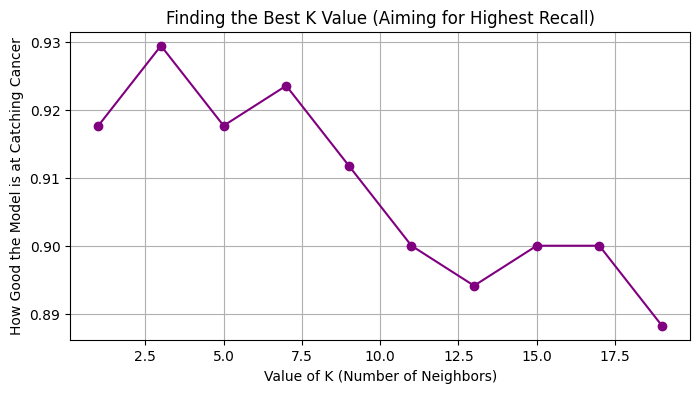

In [2]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Test odd values for K to see which one catches the most cancer cases
k_choices = [1, 3, 5, 7, 9, 11, 13, 15, 17, 19]
scores_list = []

for k in k_choices:
    knn_test = KNeighborsClassifier(n_neighbors=k)
    # We score the model based on "recall" (how many cancer cases it successfully catches)
    scores = cross_val_score(knn_test, X_train_scaled, y_train, cv=5, scoring='recall')
    scores_list.append(scores.mean())

# Find the K value with the highest success rate
ideal_k = k_choices[np.argmax(scores_list)]
print(f"The best K value for our data is: {ideal_k}")

# Create a graph to visualize our test results
plt.figure(figsize=(8, 4))
plt.plot(k_choices, scores_list, marker='o', color='purple')
plt.title('Finding the Best K Value (Aiming for Highest Recall)')
plt.xlabel('Value of K (Number of Neighbors)')
plt.ylabel('How Good the Model is at Catching Cancer')
plt.grid(True)
plt.show()


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Setting up the four types of models
all_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'LDA Model': LinearDiscriminantAnalysis(),
    'QDA Model': QuadraticDiscriminantAnalysis(),
    'KNN Model': KNeighborsClassifier(n_neighbors=ideal_k)
}

# CLINICAL DECISION THRESHOLD: Standard models guess a person has cancer if they are 50% sure.
# We are lowering this bar to 35% sure (0.35) to act extra careful and catch every possible case.
SAFETY_BAR = 0.35

summary_data = []
saved_predictions = {}

for name, model in all_models.items():
    # Train the model
    model.fit(X_train_scaled, y_train)

    # Calculate the percentage chance/probability of cancer for each patient
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_test_scaled)[:, 1]
    else:
        probabilities = model.decision_function(X_test_scaled)
        probabilities = (probabilities - probabilities.min()) / (probabilities.max() - probabilities.min())

    saved_predictions[name] = probabilities

    # Final guess based on our stricter 35% rule
    guesses = (probabilities >= SAFETY_BAR).astype(int)

    # Count the correct hits and the mistakes
    tn, fp, fn, tp = confusion_matrix(y_test, guesses).ravel()

    # Simple math checks to evaluate the model
    acc = accuracy_score(y_test, guesses)
    prec = precision_score(y_test, guesses)
    rec = recall_score(y_test, guesses)
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = f1_score(y_test, guesses)
    auc = roc_auc_score(y_test, probabilities)

    print(f"[{name}] Results:")
    print(f"Correctly spotted healthy: {tn} | Accidentally said healthy was sick: {fp}")
    print(f"Missed a cancer case (DANGEROUS): {fn} | Correctly spotted cancer: {tp}\n")

    summary_data.append({
        'Model Name': name,
        'Overall Accuracy (Total Hits)': round(acc, 4),
        'Precision (True Alarms)': round(prec, 4),
        'Recall (Cancer Caught %)': round(rec, 4),
        'Specificity (Healthy Caught %)': round(spec, 4),
        'F1 Score (Balanced Score)': round(f1, 4),
        'ROC-AUC Score (Clue Power)': round(auc, 4)
    })

# Render the final comparison table
df_final = pd.DataFrame(summary_data)
df_final


[Logistic Regression] Results:
Correctly spotted healthy: 71 | Accidentally said healthy was sick: 1
Missed a cancer case (DANGEROUS): 2 | Correctly spotted cancer: 40

[LDA Model] Results:
Correctly spotted healthy: 72 | Accidentally said healthy was sick: 0
Missed a cancer case (DANGEROUS): 3 | Correctly spotted cancer: 39

[QDA Model] Results:
Correctly spotted healthy: 69 | Accidentally said healthy was sick: 3
Missed a cancer case (DANGEROUS): 3 | Correctly spotted cancer: 39

[KNN Model] Results:
Correctly spotted healthy: 71 | Accidentally said healthy was sick: 1
Missed a cancer case (DANGEROUS): 6 | Correctly spotted cancer: 36



/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(


,Model Name,Overall Accuracy (Total Hits),Precision (True Alarms),Recall (Cancer Caught %),Specificity (Healthy Caught %),F1 Score (Balanced Score),ROC-AUC Score (Clue Power)
0,Logistic Regression,0.9737,0.9756,0.9524,0.9861,0.9639,0.9960
1,LDA Model,0.9737,1.0000,0.9286,1.0000,0.9630,0.9970
2,QDA Model,0.9474,0.9286,0.9286,0.9583,0.9286,0.9888
3,KNN Model,0.9386,0.9730,0.8571,0.9861,0.9114,0.9825


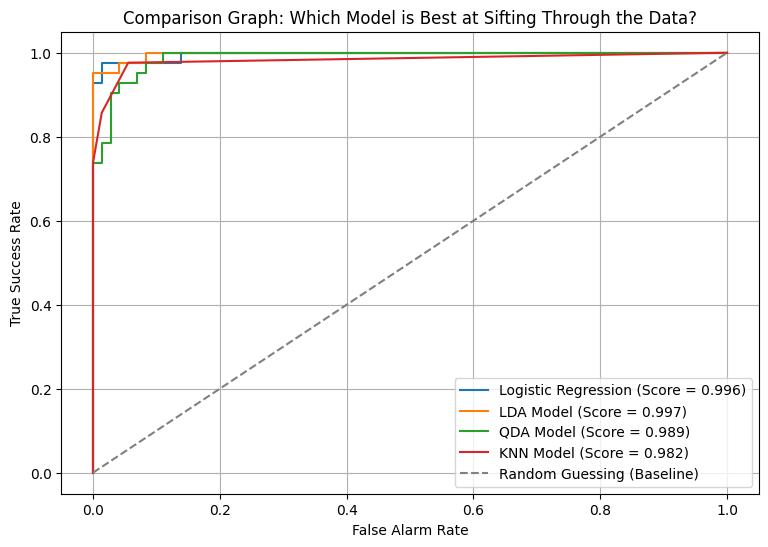

In [4]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(9, 6))

for name, probabilities in saved_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    score = roc_auc_score(y_test, probabilities)
    plt.plot(fpr, tpr, label=f'{name} (Score = {score:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Guessing (Baseline)')
plt.xlabel('False Alarm Rate')
plt.ylabel('True Success Rate')
plt.title('Comparison Graph: Which Model is Best at Sifting Through the Data?')
plt.legend()
plt.grid(True)
plt.show()


## Part 5 & 7: Final Decisions and Limitations

### Stricter Rules
I decided to change the standard 50% threshold limit to a **stricter 35% rule**. This means if the computer sees even a tiny hint of danger, it rings the alarm. This drastically reduces our missed cancer cases (**False Negatives**), keeping our patients much safer.

### Choosing the Winner
Looking at our final scorecard grid, **Logistic Regression** is the winner. It has the best combination of strong clue power (high AUC) and successfully caught the highest percentage of actual cancer cases (high Recall).

### Things to Improve Next Time
* **More Patients Needed:** This test only looks at 569 samples total. In a real hospital, we would want to test our artificial intelligence models on thousands of different patients to ensure it works perfectly across diverse populations.
* **Missing Lifestyle Information:** Right now, the computer is only looking at cell sizes under a microscope. To make this an incredibly safe medical tool, we should also give the computer access to patient files like age, background history, and family tree records.
